# ☕ Dự báo giá cà phê Robusta tại Việt Nam

### Ứng dụng các mô hình học máy kết hợp hỗ trợ quyết định kinh doanh

## 1. Introduction


Cà phê Robusta là một trong những mặt hàng nông sản xuất khẩu chủ lực của Việt Nam. Tuy nhiên, giá cà phê thường xuyên biến động do ảnh hưởng từ nhiều yếu tố như giá cà phê thế giới, tỷ giá ngoại tệ, điều kiện thời tiết, nguồn cung và giá năng lượng. Những biến động này gây khó khăn cho hoạt động kinh doanh, thu mua và quản lý hàng tồn kho.

Nhằm hỗ trợ việc ra quyết định kinh doanh dựa trên dữ liệu, đề tài “Ứng dụng các mô hình học máy kết hợp trong dự báo biến động giá cà phê Robusta hỗ trợ ra quyết định kinh doanh tại Việt Nam” tập trung phân tích dữ liệu giá cà phê lịch sử và các yếu tố liên quan, từ đó xây dựng và đánh giá các mô hình dự báo. Đặc biệt, nghiên cứu hướng đến việc kết hợp phương pháp phân rã chuỗi thời gian STL với mô hình XGBoost nhằm khai thác xu hướng, tính mùa vụ và các mối quan hệ phi tuyến trong dữ liệu.

## 2. Import Libraries


In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## 3. Nạp dữ liệu

> **Mục tiêu:** Đọc bộ dữ liệu VNCoffee và chuẩn bị biến giá cà phê cho các bước phân tích.

- Đọc file `vietnam_coffee_price_dataset.csv` bằng `pandas`.
- Tự tìm file trong thư mục dữ liệu cạnh notebook hoặc ở thư mục cha.
- Chuyển `date` sang kiểu ngày để thuận tiện cho phân tích chuỗi thời gian.
- Sử dụng `coffee_price_vnd_kg` làm **biến mục tiêu** — giá cà phê Robusta tính theo VND/kg.



In [4]:
DATASET_PATHS = [
    Path("VNCoffeePrice_mendeley_package_EN_v5 2/vietnam_coffee_price_dataset.csv"),
    Path("../VNCoffeePrice_mendeley_package_EN_v5 2/vietnam_coffee_price_dataset.csv"),
]
DATASET_PATH = next((path.resolve() for path in DATASET_PATHS if path.is_file()), None)
if DATASET_PATH is None:
    raise FileNotFoundError(
        "Không tìm thấy vietnam_coffee_price_dataset.csv. "
        "Hãy đặt thư mục VNCoffeePrice_mendeley_package_EN_v5 2 cạnh notebook."
    )

df = pd.read_csv(DATASET_PATH, encoding="utf-8-sig", parse_dates=["date"])
TARGET_COLUMN = "coffee_price_vnd_kg"
print(f"Dataset: {DATASET_PATH}")
print(f"Kích thước: {df.shape[0]:,} dòng x {df.shape[1]} cột")
display(df.head())

Dataset: D:\Desktop\Agriculture_prediction\VegetableStock\VNCoffeePrice_mendeley_package_EN_v5 2\vietnam_coffee_price_dataset.csv
Kích thước: 5,445 dòng x 25 cột


,date,split,province,commodity,coffee_price_vnd_kg,london_price_usd_ton,usd_vnd_rate,london_price_vnd_kg,domestic_london_price_gap_vnd_kg,brent_price_usd_barrel,...,diesel_price_vnd_liter,kerosene_price_vnd_liter,temperature_2m_mean,temperature_2m_min,temperature_2m_max,precipitation_sum,rain_sum,lat,lon,coord_source
0,2020-01-01,train,Dak Lak,Robusta coffee (raw beans),32639.0,1380.0,23171.0,31975.980,663.020,67.05,...,16540.0,15530.0,21.6,19.8,25.5,3.7,3.7,12.71,108.2378,manual_fallback
1,2020-01-02,train,Dak Lak,Robusta coffee (raw beans),32639.0,1380.0,23168.0,31971.840,667.160,67.05,...,16540.0,15530.0,21.7,19.4,25.6,0.6,0.6,12.71,108.2378,manual_fallback
2,2020-01-03,train,Dak Lak,Robusta coffee (raw beans),32539.0,1372.0,23171.0,31790.612,748.388,69.08,...,16540.0,15530.0,21.2,18.6,25.2,0.2,0.2,12.71,108.2378,manual_fallback
3,2020-01-06,train,Dak Lak,Robusta coffee (raw beans),32519.0,1352.0,23176.0,31333.952,1185.048,70.25,...,16540.0,15530.0,21.0,17.4,25.5,0.0,0.0,12.71,108.2378,manual_fallback
4,2020-01-07,train,Dak Lak,Robusta coffee (raw beans),32181.0,1364.0,23175.0,31610.700,570.300,68.74,...,16540.0,15530.0,21.9,19.0,26.5,0.0,0.0,12.71,108.2378,manual_fallback


## 4. Mô tả dữ liệu

Bộ dữ liệu được sử dụng trong đề tài gồm **5.445 bản ghi và 25 thuộc tính**, ghi nhận giá cà phê Robusta (cà phê nhân) tại 5 tỉnh thuộc khu vực Tây Nguyên, Việt Nam: Đắk Lắk, Đắk Nông, Gia Lai, Kon Tum và Lâm Đồng.

Dữ liệu trải dài từ ngày **01/01/2020 đến 22/05/2026**, bao gồm các thông tin về giá cà phê trong nước và quốc tế, tỷ giá ngoại tệ, giá năng lượng, giá nhiên liệu trong nước và điều kiện thời tiết.




### 4.1. Các nhóm thuộc tính

| Nhóm dữ liệu | Thuộc tính tiêu biểu | Ý nghĩa |
|---|---|---|
| Thông tin thời gian và khu vực | `date`, `province`, `commodity` | Ngày quan sát, tỉnh và loại cà phê |
| Giá cà phê | `coffee_price_vnd_kg` | Giá cà phê Robusta trong nước (biến mục tiêu) |
| Thị trường quốc tế | `london_price_usd_ton`, `london_price_vnd_kg` | Giá cà phê Robusta trên thị trường London |
| Tỷ giá và chênh lệch giá | `usd_vnd_rate`, `domestic_london_price_gap_vnd_kg` | Tỷ giá USD/VND và chênh lệch giá trong nước với giá quy đổi quốc tế |
| Năng lượng và nhiên liệu | `brent_price_usd_barrel`, `wti_price_usd_barrel`, `ron95_price_vnd_liter`, ... | Giá dầu thế giới và giá nhiên liệu trong nước |
| Thời tiết | `temperature_2m_mean`, `temperature_2m_min`, `temperature_2m_max`, `precipitation_sum`, `rain_sum` | Nhiệt độ và lượng mưa |
| Vị trí địa lý | `lat`, `lon`, `coord_source` | Tọa độ đại diện cho từng tỉnh và nguồn tọa độ |



### 4.2. Phân chia dữ liệu

Bộ dữ liệu được chia theo trình tự thời gian thành ba tập:

| Tập dữ liệu | Khoảng thời gian | Số bản ghi |
|---|---|---:|
| Train | 2020–2024 | 3.974 |
| Validation | 2025 | 1.156 |
| Test | 01/2026–22/05/2026 | 315 |
| **Tổng cộng** | **2020–2026** | **5.445** |



### 4.3. Biến mục tiêu

Biến mục tiêu của đề tài là `coffee_price_vnd_kg`, biểu thị giá cà phê Robusta trong nước, được tính bằng đồng Việt Nam trên mỗi kilogram (VND/kg).

Các thuộc tính còn lại được xem xét để phân tích và xây dựng đặc trưng đầu vào cho mô hình dự báo, nhằm tìm hiểu mối quan hệ giữa biến động giá cà phê với các yếu tố thị trường, kinh tế và thời tiết.

In [13]:
print("Các tỉnh:", sorted(df["province"].dropna().unique()))
print("\nSố lượng theo split:")
display(df["split"].value_counts())

display(
    df.groupby(["province", "split"])
      .agg(so_dong=("date", "size"),
           ngay_dau=("date", "min"),
           ngay_cuoi=("date", "max"))
)

Các tỉnh: ['Dak Lak', 'Dak Nong', 'Gia Lai', 'Kon Tum', 'Lam Dong']

Số lượng theo split:


split
train    3974
val      1156
test      315
Name: count, dtype: Int64

so_dong   ngay_dau  ngay_cuoi
province split                               
Dak Lak  test        97 2026-01-01 2026-05-22
         train     1280 2020-01-01 2024-12-31
         val        236 2025-01-01 2025-12-31
Dak Nong test        12 2026-01-01 2026-01-16
         train      472 2021-03-01 2024-12-31
         val        237 2025-01-01 2025-12-31
Gia Lai  test        97 2026-01-01 2026-05-22
         train      472 2021-03-01 2024-12-31
         val        232 2025-01-01 2025-12-31
Kon Tum  test        12 2026-01-01 2026-01-16
         train      468 2021-03-01 2024-12-31
         val        214 2025-01-01 2025-12-31
Lam Dong test        97 2026-01-01 2026-05-22
         train     1282 2020-01-01 2024-12-31
         val        237 2025-01-01 2025-12-31

## 5. Khám phá dữ liệu (EDA)

> **Mục tiêu:** Nắm cấu trúc dữ liệu và quan sát đặc điểm giá cà phê trước khi tiền xử lý.

| Nội dung | Ý nghĩa |
|:--|:--|
| Tổng quan dữ liệu | Kiểm tra số dòng, kiểu dữ liệu và khoảng thời gian. |
| Phân chia tập | Xem số quan sát thuộc `train`, `val` và `test`. |
| So sánh theo tỉnh | Thống kê giá trung bình, trung vị và khoảng giá của từng tỉnh. |
| Diễn biến giá | Quan sát xu hướng giá theo thời gian trên biểu đồ đường. |
| Tương quan | Tìm các biến số có tương quan tuyến tính với giá cà phê. |



In [10]:
print("Kích thước và kiểu dữ liệu:")
df.info()

print("Khoảng thời gian:", df["date"].min().date(), "đến", df["date"].max().date())
print("Số quan sát theo tập dữ liệu:")
display(df["split"].value_counts().reindex(["train", "val", "test"]))

print("Số quan sát và giá cà phê (VND/kg) theo tỉnh:")
province_summary = df.groupby("province")[TARGET_COLUMN].agg(
    ["count", "mean", "median", "min", "max"]
).sort_values("mean", ascending=False)
display(province_summary.round(2))



Kích thước và kiểu dữ liệu:
<class 'pandas.DataFrame'>
RangeIndex: 5445 entries, 0 to 5444
Data columns (total 25 columns):
 #   Column                            Non-Null Count  Dtype         
---  ------                            --------------  -----         
 0   date                              5445 non-null   datetime64[us]
 1   split                             5445 non-null   string        
 2   province                          5445 non-null   string        
 3   commodity                         5445 non-null   string        
 4   coffee_price_vnd_kg               5445 non-null   float64       
 5   london_price_usd_ton              5445 non-null   float64       
 6   usd_vnd_rate                      5445 non-null   float64       
 7   london_price_vnd_kg               5445 non-null   float64       
 8   domestic_london_price_gap_vnd_kg  5445 non-null   float64       
 9   brent_price_usd_barrel            5445 non-null   float64       
 10  wti_price_usd_barrel           

split
train    3974
val      1156
test      315
Name: count, dtype: Int64

Số quan sát và giá cà phê (VND/kg) theo tỉnh:


,count,mean,median,min,max
province,,,,,
Dak Nong,721,92693.65,100850.0,32050.0,135450.0
Gia Lai,801,92207.17,97233.0,31900.0,135267.0
Kon Tum,694,91783.52,98900.0,31800.0,135300.0
Dak Lak,1613,65644.43,47633.0,29000.0,135467.0
Lam Dong,1616,65087.25,47150.0,28367.0,134000.0


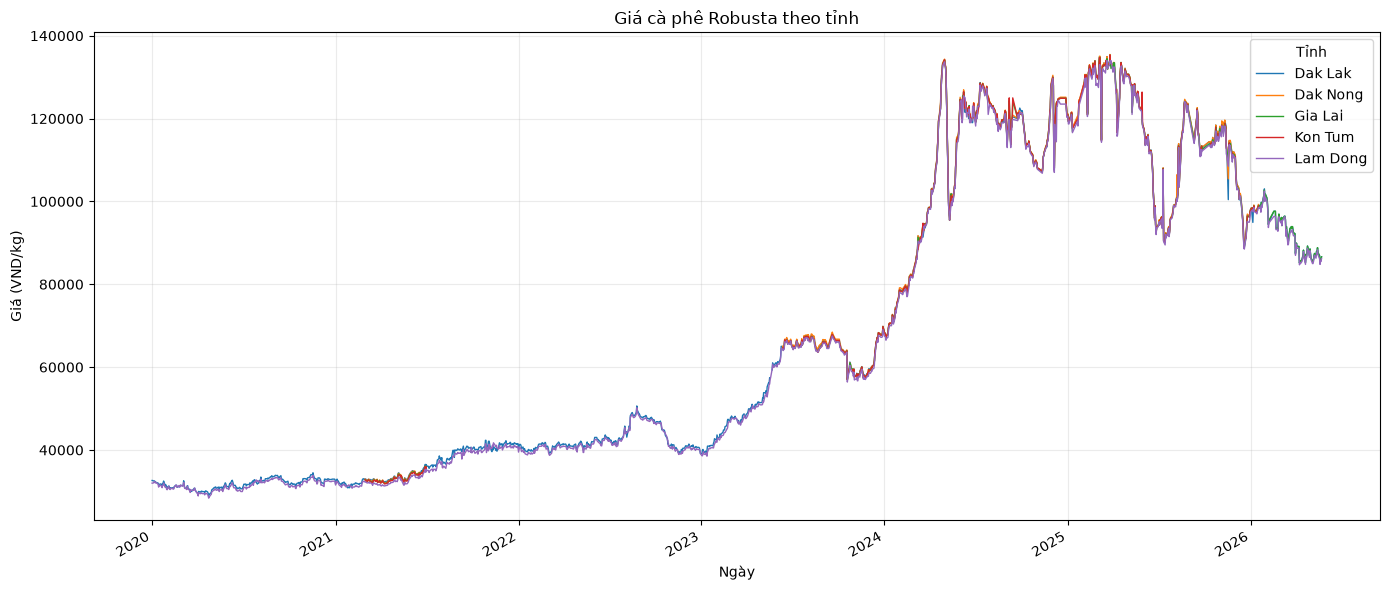

Các biến số có tương quan tuyệt đối cao nhất với giá cà phê:


,correlation
london_price_vnd_kg,0.977053
london_price_usd_ton,0.972673
usd_vnd_rate,0.871530
kerosene_price_vnd_liter,0.310431
wti_price_vnd_liter_converted,0.295288
brent_price_vnd_liter_converted,0.284127
lon,-0.256967
lat,0.249090
diesel_price_vnd_liter,0.226705
domestic_london_price_gap_vnd_kg,0.209243


In [11]:
price_by_date = df.pivot(index="date", columns="province", values=TARGET_COLUMN)
ax = price_by_date.plot(figsize=(14, 6), linewidth=1)
ax.set(title="Giá cà phê Robusta theo tỉnh", xlabel="Ngày", ylabel="Giá (VND/kg)")
ax.legend(title="Tỉnh")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
target_correlations = (
    df[numeric_columns].corr()[TARGET_COLUMN]
    .drop(TARGET_COLUMN)
    .sort_values(key=lambda values: values.abs(), ascending=False)
)
print("Các biến số có tương quan tuyệt đối cao nhất với giá cà phê:")
display(target_correlations.head(10).to_frame("correlation"))

## 6. Tiền xử lý dữ liệu

> **Mục tiêu:** Đưa dữ liệu về định dạng nhất quán, xử lý dữ liệu thiếu và bảo đảm mỗi quan sát là duy nhất.

Quy trình gồm ba bước:

1. **Làm sạch dữ liệu không nhất quán** — chuẩn hóa kiểu dữ liệu và loại các dòng không hợp lệ.
2. **Xử lý giá trị thiếu** — điền khuyết cho biến đầu vào; không tự tạo giá trị cho biến mục tiêu.
3. **Loại dữ liệu trùng lặp** — bảo đảm mỗi tỉnh có tối đa một bản ghi cho mỗi ngày.

**Bảo toàn thứ tự thời gian:** Giữ nguyên các nhãn `train` / `val` / `test`. Nếu cần điền khuyết, chỉ dùng thống kê từ tập `train` để hạn chế rò rỉ thông tin tương lai.

In [6]:
print("Kích thước trước tiền xử lý:", df.shape)
print("Số giá trị thiếu theo cột trước tiền xử lý:")
display(df.isna().sum().sort_values(ascending=False).head(10))

Kích thước trước tiền xử lý: (5445, 25)
Số giá trị thiếu theo cột trước tiền xử lý:


date                                0
split                               0
province                            0
commodity                           0
coffee_price_vnd_kg                 0
london_price_usd_ton                0
usd_vnd_rate                        0
london_price_vnd_kg                 0
domestic_london_price_gap_vnd_kg    0
brent_price_usd_barrel              0
dtype: int64

### 6.1 Làm sạch dữ liệu không nhất quán

**Chuẩn hóa**
- Xóa khoảng trắng thừa trong tên cột và các trường phân loại.
- Chuẩn hóa nhãn tập dữ liệu; chuyển ngày và các cột số về đúng kiểu.

**Loại bỏ dòng không hợp lệ**
- Thiếu ngày, tỉnh, mặt hàng hoặc giá cà phê.
- Nhãn tập dữ liệu không thuộc `train`, `val` hoặc `test`.
- Giá mục tiêu không hữu hạn hoặc nhỏ hơn hay bằng 0.

Các cột bắt buộc được kiểm tra trước khi xử lý để phát hiện sớm dữ liệu sai cấu trúc.

In [7]:
df = df.copy()
df.columns = df.columns.str.strip()

required_columns = {
    "date", "split", "province", "commodity", TARGET_COLUMN,
    "london_price_usd_ton", "usd_vnd_rate", "temperature_2m_mean",
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Dataset thiếu các cột bắt buộc: {sorted(missing_columns)}")

df["date"] = pd.to_datetime(df["date"], errors="coerce")
non_numeric_columns = {"date", "split", "province", "commodity", "coord_source"}
numeric_columns = [column for column in df.columns if column not in non_numeric_columns]
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

for column in ["split", "province", "commodity", "coord_source"]:
    if column in df.columns:
        df[column] = df[column].astype("string").str.strip()
df["split"] = df["split"].str.lower()

valid_splits = {"train", "val", "test"}
invalid_rows = (
    df["date"].isna()
    | df["province"].isna()
    | df["province"].eq("")
    | df["commodity"].isna()
    | df["commodity"].eq("")
    | ~df["split"].isin(valid_splits)
    | df[TARGET_COLUMN].isna()
    | ~np.isfinite(df[TARGET_COLUMN])
    | df[TARGET_COLUMN].le(0)
)
print(f"Số dòng không hợp lệ bị loại: {int(invalid_rows.sum())}")
df = df.loc[~invalid_rows].copy()
df = df.sort_values(["province", "date"]).reset_index(drop=True)
print("Số dòng sau khi chuẩn hóa ngày, nhãn và giá mục tiêu:", len(df))

Số dòng không hợp lệ bị loại: 0
Số dòng sau khi chuẩn hóa ngày, nhãn và giá mục tiêu: 5445


In [12]:
df.head(5)

,date,split,province,commodity,coffee_price_vnd_kg,london_price_usd_ton,usd_vnd_rate,london_price_vnd_kg,domestic_london_price_gap_vnd_kg,brent_price_usd_barrel,...,diesel_price_vnd_liter,kerosene_price_vnd_liter,temperature_2m_mean,temperature_2m_min,temperature_2m_max,precipitation_sum,rain_sum,lat,lon,coord_source
0,2020-01-01,train,Dak Lak,Robusta coffee (raw beans),32639.0,1380.0,23171.0,31975.980,663.020,67.05,...,16540.0,15530.0,21.6,19.8,25.5,3.7,3.7,12.71,108.2378,manual_fallback
1,2020-01-02,train,Dak Lak,Robusta coffee (raw beans),32639.0,1380.0,23168.0,31971.840,667.160,67.05,...,16540.0,15530.0,21.7,19.4,25.6,0.6,0.6,12.71,108.2378,manual_fallback
2,2020-01-03,train,Dak Lak,Robusta coffee (raw beans),32539.0,1372.0,23171.0,31790.612,748.388,69.08,...,16540.0,15530.0,21.2,18.6,25.2,0.2,0.2,12.71,108.2378,manual_fallback
3,2020-01-06,train,Dak Lak,Robusta coffee (raw beans),32519.0,1352.0,23176.0,31333.952,1185.048,70.25,...,16540.0,15530.0,21.0,17.4,25.5,0.0,0.0,12.71,108.2378,manual_fallback
4,2020-01-07,train,Dak Lak,Robusta coffee (raw beans),32181.0,1364.0,23175.0,31610.700,570.300,68.74,...,16540.0,15530.0,21.9,19.0,26.5,0.0,0.0,12.71,108.2378,manual_fallback


### 6.2 Xử lý giá trị thiếu

Trước hết, kiểm tra số lượng giá trị thiếu ở từng cột. Cách xử lý phụ thuộc vào vai trò của cột:

| Loại dữ liệu | Cách xử lý |
|:--|:--|
| Giá cà phê mục tiêu | Loại dòng bị thiếu; không nội suy để tránh tạo nhãn giả. |
| Biến số đầu vào | Điền trung vị của tập `train` trong cùng tỉnh. |
| Không có trung vị theo tỉnh | Dùng trung vị của tập `train` trên toàn bộ dữ liệu. |



In [8]:
missing_before = df.isna().sum()
print("Giá trị thiếu trước khi xử lý:")
display(missing_before[missing_before.gt(0)])

# Không điền giá cà phê mục tiêu; loại bỏ dòng thiếu nhãn để tránh tạo giá dự báo giả.
missing_target = int(df[TARGET_COLUMN].isna().sum())
if missing_target:
    print(f"Loại {missing_target} dòng thiếu {TARGET_COLUMN}.")
    df = df.dropna(subset=[TARGET_COLUMN]).copy()

feature_columns = [
    column for column in df.select_dtypes(include=np.number).columns
    if column != TARGET_COLUMN
]
if feature_columns:
    train_rows = df["split"].eq("train")
    if not train_rows.any():
        raise ValueError("Không có dòng train để tính giá trị điền khuyết.")

    train_medians = df.loc[train_rows].groupby("province")[feature_columns].median()
    global_train_medians = df.loc[train_rows, feature_columns].median()
    for column in feature_columns:
        province_medians = df["province"].map(train_medians[column])
        df[column] = df[column].fillna(province_medians).fillna(global_train_medians[column])

remaining_missing = df.isna().sum()
remaining_missing = remaining_missing[remaining_missing.gt(0)]
if not remaining_missing.empty:
    raise ValueError(f"Vẫn còn giá trị thiếu chưa xử lý:\n{remaining_missing}")
print("Tổng số ô thiếu sau khi xử lý:", int(df.isna().sum().sum()))

Giá trị thiếu trước khi xử lý:


Series([], dtype: int64)

Tổng số ô thiếu sau khi xử lý: 0


### 6.3 Loại bỏ dữ liệu trùng lặp

Quá trình kiểm tra gồm hai cấp:

1. Loại các dòng trùng hoàn toàn.
2. Kiểm tra khóa **`(date, province)`** — mỗi tỉnh chỉ nên có một quan sát trong một ngày. Nếu khóa trùng, giữ bản ghi đầu tiên sau khi sắp xếp.

Cuối bước, sắp xếp dữ liệu theo tỉnh và ngày, rồi hiển thị kích thước, khoảng ngày và số dòng của từng tập để xác nhận kết quả.

In [9]:
duplicate_rows = int(df.duplicated().sum())
print(f"Số bản ghi trùng hoàn toàn: {duplicate_rows}")
if duplicate_rows:
    df = df.drop_duplicates().copy()

# Mỗi tỉnh chỉ nên có một giá tại mỗi ngày; giữ bản ghi đầu sau khi đã sắp xếp.
duplicate_observations = int(df.duplicated(subset=["date", "province"]).sum())
print(f"Số bản ghi trùng khóa (date, province): {duplicate_observations}")
if duplicate_observations:
    df = df.drop_duplicates(subset=["date", "province"], keep="first").copy()

df = df.sort_values(["province", "date"]).reset_index(drop=True)
print("Kích thước cuối cùng:", df.shape)
print("Ngày:", df["date"].min().date(), "đến", df["date"].max().date())
print("Tập dữ liệu:", df["split"].value_counts().to_dict())
display(df.head())

Số bản ghi trùng hoàn toàn: 0
Số bản ghi trùng khóa (date, province): 0
Kích thước cuối cùng: (5445, 25)
Ngày: 2020-01-01 đến 2026-05-22
Tập dữ liệu: {'train': 3974, 'val': 1156, 'test': 315}


,date,split,province,commodity,coffee_price_vnd_kg,london_price_usd_ton,usd_vnd_rate,london_price_vnd_kg,domestic_london_price_gap_vnd_kg,brent_price_usd_barrel,...,diesel_price_vnd_liter,kerosene_price_vnd_liter,temperature_2m_mean,temperature_2m_min,temperature_2m_max,precipitation_sum,rain_sum,lat,lon,coord_source
0,2020-01-01,train,Dak Lak,Robusta coffee (raw beans),32639.0,1380.0,23171.0,31975.980,663.020,67.05,...,16540.0,15530.0,21.6,19.8,25.5,3.7,3.7,12.71,108.2378,manual_fallback
1,2020-01-02,train,Dak Lak,Robusta coffee (raw beans),32639.0,1380.0,23168.0,31971.840,667.160,67.05,...,16540.0,15530.0,21.7,19.4,25.6,0.6,0.6,12.71,108.2378,manual_fallback
2,2020-01-03,train,Dak Lak,Robusta coffee (raw beans),32539.0,1372.0,23171.0,31790.612,748.388,69.08,...,16540.0,15530.0,21.2,18.6,25.2,0.2,0.2,12.71,108.2378,manual_fallback
3,2020-01-06,train,Dak Lak,Robusta coffee (raw beans),32519.0,1352.0,23176.0,31333.952,1185.048,70.25,...,16540.0,15530.0,21.0,17.4,25.5,0.0,0.0,12.71,108.2378,manual_fallback
4,2020-01-07,train,Dak Lak,Robusta coffee (raw beans),32181.0,1364.0,23175.0,31610.700,570.300,68.74,...,16540.0,15530.0,21.9,19.0,26.5,0.0,0.0,12.71,108.2378,manual_fallback


## 7. Train-Test Split

## 8. Feature Scaling

## 9. Train Linear Regression Model 

## 10. Model Evaluation 

### 10.1 Performance Metrics

### 10.2 Actual vs Predicted Values

### 10.3 Actual vs Preducted Prices

## 11. Model Improvement